## Semiconductor Lab B7 - Task 1

Measure the I-U and P-I characteristics of the given laser diode in forward direction up to
100 mA. Give a statement about the quality of the contacts. Determine the threshold
current, the differential efficiency and the total efficiency of the laser diode.

In [13]:
%matplotlib inline

from pprint import pprint

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import constants
from scipy.optimize import curve_fit

from b7.python.config import DATA_DIR, PLOTS_DIR, DOUBLE_COLUMN, SINGLE_COLUMN, convert_to_nw

data_dir = DATA_DIR / "task_1_2"
export_dir = PLOTS_DIR

In [14]:
def linear(x, m, n):
    return m * x + n

### Import Data

In [15]:
file_name = "Messdaten B7 - Raumtemperatur (108.48 Ohm).csv"
df = pd.read_csv(data_dir / file_name)
df

,Diodenstrom I_D (mA),Diodenspannung V_D (mV),Optische Leistung P
0,0.09,1368,6.03 nW
1,0.21,1406,14.5 nW
2,0.31,1433,30.35 nW
3,0.40,1449,46.20 nW
4,0.50,1461,65.23 nW
5,0.61,1473,88.1 nW
6,0.72,1482,113.3 nW
7,0.80,1488,133.1 nW
8,0.90,1496,160.9 nW
9,0.99,1502,185.3 nW


### Enrich Data

#### DataFrame Enrichment

In [30]:
def enrich_data_frame(df: pd.DataFrame) -> pd.DataFrame:
    df = df.rename(columns={
        "Diodenstrom I_D (mA)": "I_mA",
        "Diodenspannung V_D (mV)": "V_mV",
    })

    # Convert Columns
    df["P_opt_nW"] = df["Optische Leistung P"].apply(convert_to_nw)

    # Add SI Base Units
    df["I"] = df["I_mA"] / 1e3
    df["V"] = df["V_mV"] / 1e3
    df["P_opt"] = df["P_opt_nW"] / 1e9
    df["P_opt_mW"] = df["P_opt_nW"] / 1e6

    df["P_el"] = df["V"] * df["I"]
    df["eta_total"] = df["P_opt"] / df["P_el"]
    df["eta_total_percent"] = df["eta_total"] * 100

    return df[["I", "V", "P_opt", "P_el", "I_mA", "V_mV", "P_opt_nW", "P_opt_mW", "eta_total", "eta_total_percent"]]

In [31]:
# Rename Columns
df_enriched = enrich_data_frame(df)
df_enriched

,I,V,P_opt,P_el,I_mA,V_mV,P_opt_nW,P_opt_mW,eta_total,eta_total_percent
0,0.00009,1.368,6.030000e-09,0.000123,0.09,1368,6.03,0.000006,0.000049,0.004898
1,0.00021,1.406,1.450000e-08,0.000295,0.21,1406,14.50,0.000015,0.000049,0.004911
2,0.00031,1.433,3.035000e-08,0.000444,0.31,1433,30.35,0.000030,0.000068,0.006832
3,0.00040,1.449,4.620000e-08,0.000580,0.40,1449,46.20,0.000046,0.000080,0.007971
4,0.00050,1.461,6.523000e-08,0.000731,0.50,1461,65.23,0.000065,0.000089,0.008930
5,0.00061,1.473,8.810000e-08,0.000899,0.61,1473,88.10,0.000088,0.000098,0.009805
6,0.00072,1.482,1.133000e-07,0.001067,0.72,1482,113.30,0.000113,0.000106,0.010618
7,0.00080,1.488,1.331000e-07,0.001190,0.80,1488,133.10,0.000133,0.000112,0.011181
8,0.00090,1.496,1.609000e-07,0.001346,0.90,1496,160.90,0.000161,0.000120,0.011950
9,0.00099,1.502,1.853000e-07,0.001487,0.99,1502,185.30,0.000185,0.000125,0.012461


#### Linear Fit

In [18]:
# Generic Fit
mask = df_enriched["I"] > 0.0125
(m, n), cov = curve_fit(linear, df_enriched[mask]["I"], df_enriched[mask]["P_opt"])
fit_data = {
    "m": {
        "value": m,
        "delta": np.sqrt(cov[0, 0])
    },
    "n": {
        "value": n,
        "delta": np.sqrt(cov[1, 1])
    }
}
pprint(fit_data)

{'m': {'delta': np.float64(0.0003320382978683906),
       'value': np.float64(0.14635714283970136)},
 'n': {'delta': np.float64(5.531203973925937e-06),
       'value': np.float64(-0.0018744928568550684)}}


#### Calculated Quantities

In [19]:
I_th = -n / m

first_term = fit_data["n"]["delta"] / fit_data["m"]["value"]
second_term = fit_data["n"]["value"] * fit_data["m"]["delta"] / fit_data["m"]["value"]**2
delta_I_th = np.sqrt(first_term ** 2 + second_term ** 2)

calculated_data = {
    "I_th": {
        "value": I_th,
        "delta": delta_I_th
    }
}

In [20]:
WAVELENGTH = 800e-9  # 800 nm
eta_diff = fit_data["m"]["value"] * constants.e * WAVELENGTH / (constants.h * constants.c)
eta_diff_delta = fit_data["m"]["delta"] * constants.e * WAVELENGTH / (constants.h * constants.c)
calculated_data["eta_diff"] = {
    "value": eta_diff,
    "delta": eta_diff_delta
}


In [21]:
pprint(calculated_data)

{'I_th': {'delta': np.float64(4.767134676776803e-05),
          'value': np.float64(0.01280766227384009)},
 'eta_diff': {'delta': np.float64(0.00021424555842721192),
              'value': np.float64(0.09443599728948048)}}


### Plot Data

#### Preparation

In [22]:
# Fit line, sampled over the lasing branch
left_padding = 0.0005
I_plot = np.linspace(min(df_enriched["I"][mask]) - left_padding, max(df_enriched["I"][mask]), 100)
P_plot = linear(I_plot, m, n)

# Milli-scaled quantities, so the plot cells carry no unit arithmetic
I_plot_mA = I_plot * 1e3
P_plot_mW = P_plot * 1e3
I_th_mA = calculated_data["I_th"]["value"] * 1e3

#### Main Plots

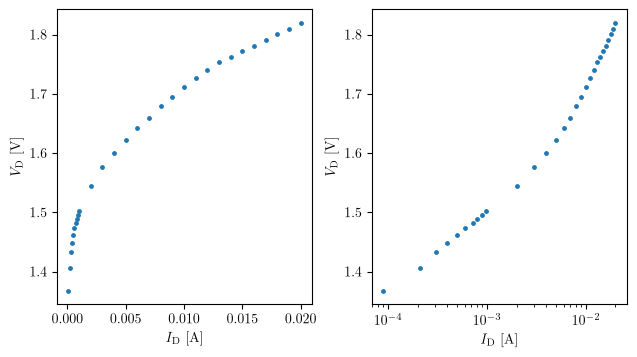

In [23]:
with plt.rc_context(DOUBLE_COLUMN):
    fig, (ax1, ax2) = plt.subplots(ncols=2, layout="constrained")

    ax1.scatter(df_enriched["I"], df_enriched["V"], s=6)
    ax1.set_xlabel(r"$I_\mathrm{D}$ [\unit{\ampere}]")
    ax1.set_ylabel(r"$V_\mathrm{D}$ [\unit{\volt}]")

    ax2.scatter(df_enriched["I"], df_enriched["V"], s=6)
    ax2.set_xscale("log")
    ax2.set_xlabel(r"$I_\mathrm{D}$ [\unit{\ampere}]")
    ax2.set_ylabel(r"$V_\mathrm{D}$ [\unit{\volt}]")

    plt.show()

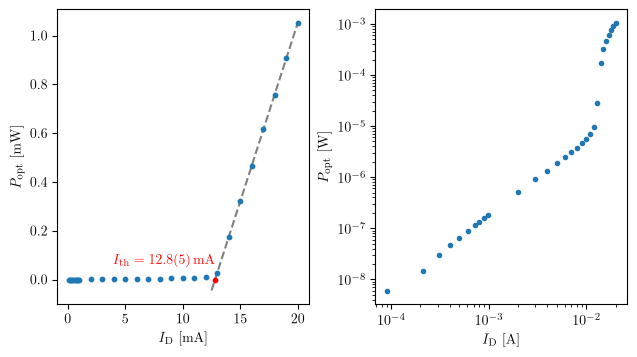

In [24]:
offset_right = 0.0035
offset_top = 0.05
text = r"$I_{\mathrm{th}}=\qty{12.8(5)}{\milli\ampere}$"

with plt.rc_context(DOUBLE_COLUMN):
    fig, (ax1, ax2) = plt.subplots(ncols=2, layout="constrained")

    ax1.scatter(df_enriched["I_mA"], df_enriched["P_opt_mW"], s=10)
    ax1.plot(I_plot_mA, P_plot_mW, color="grey", zorder=-1, linestyle="--")
    ax1.scatter(I_th_mA, 0, color="red", s=10)
    ax1.text(I_th_mA - offset_right, offset_top, s=text, va="bottom", ha="right", color="red")
    ax1.set_xlabel(r"$I_\mathrm{D}$ [\unit{\milli\ampere}]")
    ax1.set_ylabel(r"$P_\mathrm{opt}$ [\unit{\milli\watt}]")

    ax2.scatter(df_enriched["I"], df_enriched["P_opt"], s=9)
    ax2.loglog()
    ax2.set_xlabel(r"$I_\mathrm{D}$ [\unit{\ampere}]")
    ax2.set_ylabel(r"$P_\mathrm{opt}$ [\unit{\watt}]")

    plt.show()

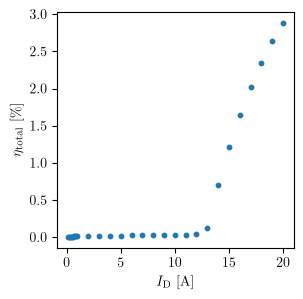

In [37]:
with plt.rc_context(SINGLE_COLUMN):
    fig, ax = plt.subplots()
    ax.scatter(df_enriched["I_mA"], df_enriched["eta_total_percent"], s=10)
    ax.set_xlabel(r"$I_\mathrm{D}$ [\unit{\ampere}]")
    ax.set_ylabel(r"$\eta_\mathrm{total}$ [\unit{\percent}]")

    plt.show()